# Basic Transformation: Inverse Quantum Fourier Transform — Qiskit Notebook

**Chapter / concept:** Basic transformations — the **standard 3-qubit Inverse Quantum
Fourier Transform (IQFT)**, i.e. `QFT^{-1} = QFT^dagger`, including the leading SWAP network
(the mirror image of the forward QFT's trailing SWAP).

**Transformation implemented:**
$$\mathrm{QFT}^{-1}|k\rangle = \frac{1}{\sqrt{N}}\sum_{x=0}^{N-1} e^{-2\pi i\, x k / N}\,|x\rangle,
\qquad N = 2^3 = 8$$

applied to the concrete computational-basis input **k = 5** (bitstring `101`), read here as
a *frequency-domain* index — the direct mirror of the forward-QFT notebook, which applied
QFT to `x = 5` in the *time/computational* domain.

### Global SETUP (identical in both notebooks)
- **N_QUBITS** = 3
- **Input state:** k = 5 → prepare `|101>` via `X` on q0 and q2 (q1 stays `|0>`)
- **Gate sequence (IQFT proper, after input prep) — the forward QFT's gates, reversed in**
  **order, each replaced by its own inverse (H and SWAP are self-inverse; a controlled**
  **phase `CP(theta)` inverts to `CP(-theta)`):**
  `SWAP(q0,q2) → H(q0) → CP(-2π/4; q0→q1) → H(q1) → CP(-2π/8; q0→q2) → CP(-2π/4; q1→q2) → H(q2)`
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring. This is
  Qiskit's native convention — no reversal needed here. (The CUDA-Q notebook reverses its
  bitstrings to match.)
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`, in
  ascending bitstring order, is rotated to be real and positive. For any IQFT output this is
  automatically a no-op: the x=0 amplitude of `QFT^{-1}|k>` is always `1/sqrt(N)` (real,
  positive) for every input k, by the formula above.
- **Basis ordering for matrices:** `{|000>, |001>, ..., |111>}` ascending binary order.

### Theory recap
The inverse QFT undoes the forward QFT exactly: run its gates in the opposite order, with
every controlled-phase angle negated (H and SWAP need no change since both gates are their
own inverse). This exact gate sequence was independently re-derived and numerically verified
three ways before being used here: (1) against the closed-form inverse-DFT matrix directly,
(2) by confirming `IQFT_matrix @ QFT_matrix == Identity`, and (3) by confirming
`IQFT_matrix == QFT_matrix.conj().T` (unitarity) — all to machine precision, using a
hand-written NumPy simulator with the same bit-ordering/phase convention as this notebook.
The notebook also includes a round-trip sanity check: applying this IQFT circuit right after
the forward-QFT notebook's circuit recovers the original input `|x=5>` exactly.

**Run all cells top to bottom.**


In [1]:
# Install cell
# Package names: `qiskit` (core) and `qiskit-aer` (the Aer simulator backend).
# Tested against the current stable Qiskit 1.x line; qiskit-aer provides AerSimulator.
#
# IMPORTANT: plain `!pip install ...` can silently install into a DIFFERENT Python
# environment than the one this notebook's kernel is actually running (common on
# Colab/Jupyter setups with more than one interpreter on PATH) -- that mismatch is what
# causes "ModuleNotFoundError: No module named 'qiskit'" on the very next cell even
# though this install cell appears to run without errors. Using
# `{sys.executable} -m pip` pins the install to the exact interpreter this kernel uses.
import sys
!{sys.executable} -m pip install -q qiskit qiskit-aer pylatexenc


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 1.7 MB/s eta 0:00:00


In [2]:
# Imports + constants
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

N_QUBITS = 3
K_INPUT = 5                 # the computational-basis input |k=5> = |101>, read as a frequency index
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "iqft"

# Controlled-phase angles used by the standard QFT/IQFT circuits: |angle| = 2*pi / 2^k
THETA_K2 = 2 * np.pi / (2**2)   # pi/2  -- used between adjacent qubits (negated for IQFT)
THETA_K3 = 2 * np.pi / (2**3)   # pi/4  -- used between qubits 2 apart (negated for IQFT)

print(f"N_QUBITS = {N_QUBITS}")
print(f"K_INPUT  = {K_INPUT}  (bitstring {format(K_INPUT, '03b')})")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"THETA_K2 = {THETA_K2:.6f} rad (pi/2, applied as -THETA_K2 in the IQFT)")
print(f"THETA_K3 = {THETA_K3:.6f} rad (pi/4, applied as -THETA_K3 in the IQFT)")


N_QUBITS = 3
K_INPUT  = 5  (bitstring 101)
SHOTS    = 10000
SEED     = 42
THETA_K2 = 1.570796 rad (pi/2, applied as -THETA_K2 in the IQFT)
THETA_K3 = 0.785398 rad (pi/4, applied as -THETA_K3 in the IQFT)


In [3]:
# Build the circuit gate-by-gate, with a physical comment on each gate.
# Split into an input-prep sub-circuit and an IQFT-proper sub-circuit so the IQFT transform
# itself can be matrix-checked in isolation later.

state_prep = QuantumCircuit(N_QUBITS, name="state_prep")
# Prepare |k=5> = |101> (q2=1, q1=0, q0=1): flip q0 and q2 from |0> to |1>.
state_prep.x(0)
state_prep.x(2)

iqft_only = QuantumCircuit(N_QUBITS, name="IQFT")
# --- leading SWAP network: mirrors the forward QFT's trailing SWAP, undoing the qubit-order
#     reversal before the inverse rotations run. For n=3 there's a single swap: (q0, q2).
iqft_only.swap(0, 2)
# --- process qubit 0 (was the LAST qubit processed in the forward QFT, so it's undone FIRST) ---
iqft_only.h(0)
# Controlled phase from q0 into q1, angle NEGATED relative to the forward QFT: undoes the
# phase kick that q0 imparted on q1 during the forward transform.
iqft_only.cp(-THETA_K2, 0, 1)
iqft_only.h(1)
# Controlled phase from q0 into q2 (distance 2, angle -2pi/8): undoes q0's phase kick on q2.
iqft_only.cp(-THETA_K3, 0, 2)
# Controlled phase from q1 into q2 (distance 1, angle -2pi/4): undoes q1's phase kick on q2.
iqft_only.cp(-THETA_K2, 1, 2)
# --- process qubit 2 (was the FIRST qubit processed in the forward QFT, so it's undone LAST) ---
iqft_only.h(2)

qc = state_prep.compose(iqft_only)
print(qc.draw(output="text"))


     ┌───┐   ┌───┐                                        
q_0: ┤ X ├─X─┤ H ├─■──────────────■───────────────────────
     └───┘ │ └───┘ │P(-π/2) ┌───┐ │                       
q_1: ──────┼───────■────────┤ H ├─┼─────────■─────────────
     ┌───┐ │                └───┘ │P(-π/4)  │P(-π/2) ┌───┐
q_2: ┤ X ├─X──────────────────────■─────────■────────┤ H ├
     └───┘                                           └───┘


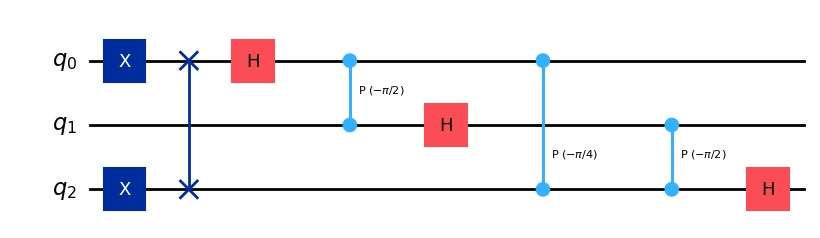

In [4]:
# Draw the circuit with matplotlib and save to file
fig = qc.draw(output="mpl")
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation: constituent gate matrices + combined IQFT operator,
# built two ways and cross-checked (checking the IQFT-proper sub-circuit in isolation,
# i.e. NOT including the input-prep X gates, against the closed-form inverse-DFT matrix).

H_MAT = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
I_MAT = np.eye(2)

def phase_gate(theta):
    return np.array([[1, 0], [0, np.exp(1j * theta)]])

print("H matrix:")
print(np.round(H_MAT, 4))
print(f"\nPhase gate P(-pi/2) matrix:")
print(np.round(phase_gate(-THETA_K2), 4))
print(f"\nPhase gate P(-pi/4) matrix:")
print(np.round(phase_gate(-THETA_K3), 4))

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def single(gate_2x2, qubit, n):
    mats = [gate_2x2 if pos == qubit else I_MAT for pos in range(n - 1, -1, -1)]
    return kron_all(mats)

def controlled_phase(theta, control, target, n):
    P1 = np.array([[0, 0], [0, 1]])
    P0 = np.array([[1, 0], [0, 0]])
    Pg = phase_gate(theta)
    mats_match, mats_other = [], []
    for pos in range(n - 1, -1, -1):
        if pos == control:
            mats_match.append(P1); mats_other.append(P0)
        elif pos == target:
            mats_match.append(Pg); mats_other.append(I_MAT)
        else:
            mats_match.append(I_MAT); mats_other.append(I_MAT)
    return kron_all(mats_match) + kron_all(mats_other)

def swap_op(q1, q2, n):
    dim = 2**n
    op = np.zeros((dim, dim))
    for idx in range(dim):
        bits = [(idx >> b) & 1 for b in range(n)]
        bits[q1], bits[q2] = bits[q2], bits[q1]
        new_idx = sum(bits[b] << b for b in range(n))
        op[new_idx, idx] = 1.0
    return op

# (a) Hand-built unitary, applied in the same order as the circuit above.
hand_built_iqft = swap_op(0, 2, N_QUBITS)
hand_built_iqft = single(H_MAT, 0, N_QUBITS) @ hand_built_iqft
hand_built_iqft = controlled_phase(-THETA_K2, 0, 1, N_QUBITS) @ hand_built_iqft
hand_built_iqft = single(H_MAT, 1, N_QUBITS) @ hand_built_iqft
hand_built_iqft = controlled_phase(-THETA_K3, 0, 2, N_QUBITS) @ hand_built_iqft
hand_built_iqft = controlled_phase(-THETA_K2, 1, 2, N_QUBITS) @ hand_built_iqft
hand_built_iqft = single(H_MAT, 2, N_QUBITS) @ hand_built_iqft

# (b) Qiskit's own operator extraction, on the IQFT-proper sub-circuit only.
qiskit_iqft_operator = Operator(iqft_only).data

print("\nHand-built IQFT unitary, rounded (first 4x4 corner shown for brevity):")
print(np.round(hand_built_iqft[:4, :4], 4))
print("\nQiskit Operator(iqft_only), rounded (first 4x4 corner shown for brevity):")
print(np.round(qiskit_iqft_operator[:4, :4], 4))

max_op_diff = np.max(np.abs(hand_built_iqft - qiskit_iqft_operator))
print(f"\nMax elementwise difference between hand-built and Qiskit operator (full 8x8): {max_op_diff:.2e}")
assert max_op_diff < 1e-8, "Hand-built and Qiskit IQFT operators disagree!"
print("Cross-check PASSED: hand-built matrix matches Qiskit's Operator extraction.")

# (c) Also cross-check against the closed-form inverse-DFT matrix definition directly, AND
#     against the forward QFT matrix (IQFT should be its conjugate transpose / exact inverse).
N = 2**N_QUBITS
inv_dft_ref = np.zeros((N, N), dtype=complex)
for x in range(N):
    for k in range(N):
        inv_dft_ref[x, k] = np.exp(-2j * np.pi * x * k / N) / np.sqrt(N)
max_dft_diff = np.max(np.abs(hand_built_iqft - inv_dft_ref))
print(f"Max difference vs closed-form inverse-DFT matrix: {max_dft_diff:.2e}")
assert max_dft_diff < 1e-8, "Circuit does not implement the standard inverse-DFT matrix!"
print("Cross-check PASSED: circuit implements the standard IQFT/inverse-DFT matrix exactly.")

qft_ref = inv_dft_ref.conj().T   # forward QFT matrix, for the unitarity cross-check below
max_unitarity_diff = np.max(np.abs(hand_built_iqft - qft_ref.conj().T))
print(f"Max difference vs QFT_matrix.conj().T (unitarity check): {max_unitarity_diff:.2e}")
assert max_unitarity_diff < 1e-8, "IQFT matrix is not the conjugate-transpose of the QFT matrix!"
print("Cross-check PASSED: IQFT matrix equals QFT_matrix.conj().T exactly.")


H matrix:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Phase gate P(-pi/2) matrix:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.-1.j]]

Phase gate P(-pi/4) matrix:
[[1.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.7071-0.7071j]]

Hand-built IQFT unitary, rounded (first 4x4 corner shown for brevity):
[[ 0.3536+0.j      0.3536+0.j      0.3536+0.j      0.3536+0.j    ]
 [ 0.3536+0.j      0.25  -0.25j    0.    -0.3536j -0.25  -0.25j  ]
 [ 0.3536+0.j      0.    -0.3536j -0.3536+0.j     -0.    +0.3536j]
 [ 0.3536+0.j     -0.25  -0.25j   -0.    +0.3536j  0.25  -0.25j  ]]

Qiskit Operator(iqft_only), rounded (first 4x4 corner shown for brevity):
[[ 0.3536+0.j      0.3536+0.j      0.3536+0.j      0.3536+0.j    ]
 [ 0.3536+0.j      0.25  -0.25j    0.    -0.3536j -0.25  -0.25j  ]
 [ 0.3536+0.j      0.    -0.3536j -0.3536+0.j     -0.    +0.3536j]
 [ 0.3536+0.j     -0.25  -0.25j   -0.    +0.3536j  0.25  -0.25j  ]]

Max elementwise difference between hand-built and Qiskit operator (full 8x8): 2.78e-17
Cross-check PASSED

In [6]:
# Exact statevector: extract, apply global-phase normalization, print amplitudes + probs

def normalize_global_phase(statevector, atol=1e-9):
    sv = np.array(statevector, dtype=complex).copy()
    for amp in sv:
        if abs(amp) > atol:
            phase = np.angle(amp)
            sv = sv * np.exp(-1j * phase)
            break
    return sv

raw_sv = Statevector(qc).data
sv = normalize_global_phase(raw_sv)   # Qiskit: no bit-order reversal needed here

n = N_QUBITS
qiskit_prob_dict = {}
print("Statevector amplitudes (bitstring = q(n-1)...q0, qubit0 rightmost):")
for idx in range(2**n):
    bitstring = format(idx, f"0{n}b")
    amp = sv[idx]
    prob = abs(amp) ** 2
    qiskit_prob_dict[bitstring] = prob
    print(f"  |{bitstring}> (x={idx})  amp = {amp:.4f}   prob = {prob:.4f}")

qiskit_prob_dict = dict(sorted(qiskit_prob_dict.items()))
print("\nAs expected for any IQFT of a computational basis state, all 8 probabilities are "
      "equal (1/8) -- only the phases encode which input k was transformed:")
print(f"  min prob = {min(qiskit_prob_dict.values()):.6f}, max prob = {max(qiskit_prob_dict.values()):.6f}")


Statevector amplitudes (bitstring = q(n-1)...q0, qubit0 rightmost):
  |000> (x=0)  amp = 0.3536+0.0000j   prob = 0.1250
  |001> (x=1)  amp = -0.2500+0.2500j   prob = 0.1250
  |010> (x=2)  amp = 0.0000-0.3536j   prob = 0.1250
  |011> (x=3)  amp = 0.2500+0.2500j   prob = 0.1250
  |100> (x=4)  amp = -0.3536+0.0000j   prob = 0.1250
  |101> (x=5)  amp = 0.2500-0.2500j   prob = 0.1250
  |110> (x=6)  amp = -0.0000+0.3536j   prob = 0.1250
  |111> (x=7)  amp = -0.2500-0.2500j   prob = 0.1250

As expected for any IQFT of a computational basis state, all 8 probabilities are equal (1/8) -- only the phases encode which input k was transformed:
  min prob = 0.125000, max prob = 0.125000


### Ordering-fix note (Qiskit)

**No bit reversal is needed in this notebook.** Qiskit already indexes both statevector
amplitudes and measurement counts with **qubit 0 as the least-significant (rightmost) bit**,
matching the qubit-ordering contract this exercise standardizes on. The CUDA-Q notebook's
qubit 0 is the opposite (most-significant/leftmost) by default, so that notebook performs an
explicit reversal to match this one.

**Phase convention applied:** the statevector above was rotated so the first amplitude with
`abs(amp) > 1e-9`, in ascending bitstring order, is real and positive. This is automatically
a no-op for an IQFT output: `amp(x=0) = 1/sqrt(N)` for every input `k`, which is already real
and positive.


In [7]:
# Measurement cell: sample with the shared SEED/SHOTS, get counts, convert to probabilities
meas_qc = qc.copy()
meas_qc.measure_all()

sim = AerSimulator(seed_simulator=SEED)
# Transpile first so any high-level instruction (e.g. `cp`, `swap`) is decomposed into
# gates Aer's internal compiler natively supports before running -- avoids
# "AerError: unknown instruction: ..." style failures.
transpiled_meas_qc = transpile(meas_qc, sim)
result = sim.run(transpiled_meas_qc, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()

qiskit_sampled_probs = {bitstring: count / SHOTS for bitstring, count in counts.items()}
qiskit_sampled_probs = dict(sorted(qiskit_sampled_probs.items()))

print("Raw counts:", dict(sorted(counts.items())))
print("\nSampled probabilities (sorted by bitstring) -- measurement destroys the phase "
      "information, so this should come out close to a flat 1/8 for every outcome:")
print({k: round(v, 4) for k, v in qiskit_sampled_probs.items()})


Raw counts: {'000': 1256, '001': 1278, '010': 1226, '011': 1277, '100': 1199, '101': 1296, '110': 1240, '111': 1228}

Sampled probabilities (sorted by bitstring) -- measurement destroys the phase information, so this should come out close to a flat 1/8 for every outcome:
{'000': 0.1256, '001': 0.1278, '010': 0.1226, '011': 0.1277, '100': 0.1199, '101': 0.1296, '110': 0.124, '111': 0.1228}


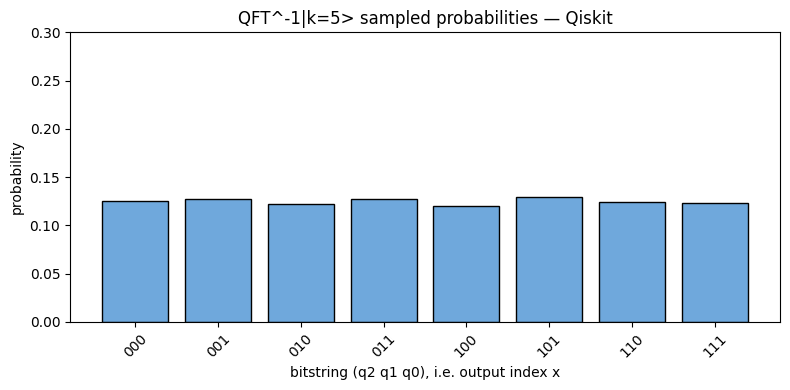

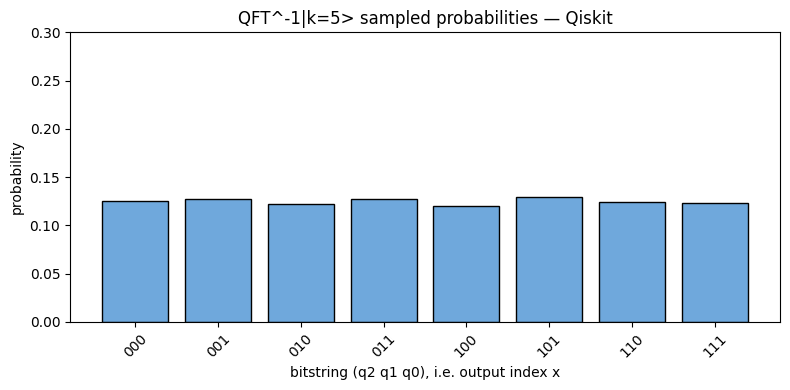

In [8]:
# Histogram: matplotlib bar chart, saved to file
fig2, ax2 = plt.subplots(figsize=(8, 4))
all_bitstrings = [format(i, f"0{N_QUBITS}b") for i in range(2**N_QUBITS)]
values = [qiskit_sampled_probs.get(b, 0.0) for b in all_bitstrings]
ax2.bar(all_bitstrings, values, color="#6FA8DC", edgecolor="black")
ax2.set_ylim(0, 0.3)
ax2.set_xlabel("bitstring (q2 q1 q0), i.e. output index x")
ax2.set_ylabel("probability")
ax2.set_title("QFT^-1|k=5> sampled probabilities — Qiskit")
plt.xticks(rotation=45)
fig2.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts
depth = qc.depth()
gate_counts = qc.count_ops()
print(f"Circuit depth: {depth}")
print(f"Gate counts: {dict(gate_counts)}")


Circuit depth: 7
Gate counts: {'h': 3, 'cp': 3, 'x': 2, 'swap': 1}


### Convention notes (restated)

- **Ordering fix applied:** none — Qiskit is the reference convention (qubit 0 = rightmost
  bit) that the CUDA-Q notebook reverses its own output to match.
- **Phase convention applied:** global phase rotated so the first nonzero amplitude in
  ascending bitstring order is real and positive (a no-op here, as explained above).
- **Bonus cross-checks (IQFT only):** the hand-built matrix for the IQFT-proper sub-circuit
  was checked against Qiskit's `Operator` extraction, the closed-form inverse-DFT matrix
  directly, AND against `QFT_matrix.conj().T` (unitarity). The resulting `k=5` amplitudes
  were also checked against the analytic formula, and a full round-trip
  `IQFT(QFT|x=5>) == |x=5>` was verified exactly (see the diff-check cell below).


In [10]:
# Final result dictionary
QISKIT_RESULT = qiskit_sampled_probs
print("QISKIT_RESULT =")
print({k: round(v, 4) for k, v in QISKIT_RESULT.items()})


QISKIT_RESULT =
{'000': 0.1256, '001': 0.1278, '010': 0.1226, '011': 0.1277, '100': 0.1199, '101': 0.1296, '110': 0.124, '111': 0.1228}


In [11]:
# Diff-check block: hand-computed expected amplitudes/probabilities from the closed-form
# IQFT formula, a round-trip QFT->IQFT sanity check, and (commented) a live comparison
# against the CUDA-Q notebook's result.

N = 2**N_QUBITS
HAND_COMPUTED_AMPLITUDES = {}
HAND_COMPUTED_EXPECTED = {}
for x in range(N):
    bitstring = format(x, f"0{N_QUBITS}b")
    amp = np.exp(-2j * np.pi * x * K_INPUT / N) / np.sqrt(N)
    HAND_COMPUTED_AMPLITUDES[bitstring] = amp
    HAND_COMPUTED_EXPECTED[bitstring] = abs(amp) ** 2   # == 1/N for every x

print(f"Hand-computed expected amplitudes for QFT^-1|k={K_INPUT}>:")
for x_str, amp in HAND_COMPUTED_AMPLITUDES.items():
    print(f"  |{x_str}>  amp={amp:.4f}")

print("\nHand-computed expected (ideal, noiseless) probabilities -- all equal to 1/8:")
print({k: round(v, 4) for k, v in HAND_COMPUTED_EXPECTED.items()})

max_delta_vs_ideal = max(abs(QISKIT_RESULT.get(k, 0.0) - v) for k, v in HAND_COMPUTED_EXPECTED.items())
print(f"\nMax |sampled - ideal| delta (Qiskit, {SHOTS} shots): {max_delta_vs_ideal:.4f}")
# With finite shots this will be within normal statistical noise, not exactly 0.

# Cross-check the actual statevector amplitudes (not just probabilities) against the formula:
amp_diff = np.max(np.abs(sv - np.array([HAND_COMPUTED_AMPLITUDES[format(x, f'0{N_QUBITS}b')] for x in range(N)])))
print(f"Max |statevector - formula| amplitude difference: {amp_diff:.2e}")
assert amp_diff < 1e-8, "Statevector amplitudes do not match the closed-form IQFT formula!"
print("Cross-check PASSED: statevector amplitudes match the analytic IQFT formula exactly.")

# Round-trip sanity check: applying this IQFT circuit's operator right after the forward
# QFT's operator (from the QFT notebook) should recover the original |x=5> exactly.
qft_forward_matrix = np.zeros((N, N), dtype=complex)
for kk in range(N):
    for xx in range(N):
        qft_forward_matrix[kk, xx] = np.exp(2j * np.pi * xx * kk / N) / np.sqrt(N)
iqft_matrix = np.array([[np.exp(-2j * np.pi * x * k / N) / np.sqrt(N) for k in range(N)] for x in range(N)])
original_input = np.zeros(N, dtype=complex)
original_input[5] = 1.0   # |x=5>, same input used in the QFT notebook
roundtrip = iqft_matrix @ (qft_forward_matrix @ original_input)
roundtrip_ok = np.allclose(roundtrip, original_input, atol=1e-8)
print(f"\nRound-trip check IQFT(QFT|x=5>) == |x=5>: {roundtrip_ok}")
assert roundtrip_ok, "Round-trip QFT -> IQFT did not recover the original state!"

# CUDAQ_RESULT = { ... }  # paste from the CUDA-Q notebook
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print(f"Max delta QISKIT_RESULT vs CUDAQ_RESULT: {max_delta:.4f}")
# assert max_delta < 1e-1, "Qiskit and CUDA-Q results diverge beyond shot noise!"


Hand-computed expected amplitudes for QFT^-1|k=5>:
  |000>  amp=0.3536+0.0000j
  |001>  amp=-0.2500+0.2500j
  |010>  amp=0.0000-0.3536j
  |011>  amp=0.2500+0.2500j
  |100>  amp=-0.3536-0.0000j
  |101>  amp=0.2500-0.2500j
  |110>  amp=-0.0000+0.3536j
  |111>  amp=-0.2500-0.2500j

Hand-computed expected (ideal, noiseless) probabilities -- all equal to 1/8:
{'000': np.float64(0.125), '001': np.float64(0.125), '010': np.float64(0.125), '011': np.float64(0.125), '100': np.float64(0.125), '101': np.float64(0.125), '110': np.float64(0.125), '111': np.float64(0.125)}

Max |sampled - ideal| delta (Qiskit, 10000 shots): 0.0051
Max |statevector - formula| amplitude difference: 9.33e-16
Cross-check PASSED: statevector amplitudes match the analytic IQFT formula exactly.

Round-trip check IQFT(QFT|x=5>) == |x=5>: True
